# AA 279B Homework 1


## Problem 1

In [166]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [167]:
import numpy as np
from scipy.optimize import root_scalar
import matplotlib.pyplot as plt

In [168]:
# km3/s2
MU_PLUTO = 870.9
MU_CHARON = 101.0

# km
r_PLUTO_CHARON = 19571.0 
R_PLUTO = 1184.0
R_CHARON = 603.5

### Part (a)

In [169]:
T_pluto = 2 * np.pi * np.sqrt(R_PLUTO**3 / MU_PLUTO)

print(f"T_pluto: {T_pluto} sec ({T_pluto/60} min)")

T_pluto: 8674.077071700143 sec (144.5679511950024 min)


### Part (b)

In [170]:
mu_star = MU_CHARON / (MU_CHARON + MU_PLUTO)

# Barycenter -> pluto
r_bc_pluto = mu_star * r_PLUTO_CHARON
inside_pluto = r_bc_pluto < R_PLUTO

# Barycenter -> charon
r_bc_charon = (1 - mu_star) * r_PLUTO_CHARON


print(f"Barycenter distance from Pluto: {r_bc_pluto:.2f}km")
print(f"Inside pluto? ({R_PLUTO:.2f}km): {inside_pluto}")

Barycenter distance from Pluto: 2033.82km
Inside pluto? (1184.00km): False


### Part (c)

In [171]:
w_s = np.sqrt( (MU_PLUTO + MU_CHARON) / r_PLUTO_CHARON**3)

In [172]:
# No direction, just values

def a_pluto(x):
    return MU_PLUTO / (x + r_bc_pluto)**2
    
def a_charon(x):
    return MU_CHARON / (x - r_bc_charon)**2
    
def a_cent(x):
    return w_s**2*x

In [173]:
# Lowkey using arbitrary bounds

# Force balance 
r_L1 = root_scalar(
    lambda x: a_pluto(x) - a_charon(x) - a_cent(x),
    bracket=[0, r_bc_charon - 0.001]).root


print(f"L1 location: {r_L1:.2f} km (from barycenter)")
print(f"             {(r_L1 + r_bc_pluto):.2f} km (from pluto)")
print(f"             {(r_bc_charon - r_L1):.2f} km (from charon)")

L1 location: 11774.28 km (from barycenter)
             13808.10 km (from pluto)
             5762.90 km (from charon)


In [201]:
# Completeness

r_L2 = root_scalar(
    lambda x: a_pluto(x) + a_charon(x) - a_cent(x),
    bracket=[r_bc_charon - 0.001, r_bc_charon*2]).root

r_L3 = root_scalar(
    lambda x: -a_pluto(x) - a_charon(x) - a_cent(x),
    bracket=[-r_bc_charon * 2, -r_bc_pluto + 0.001]).root

x_L4_L5 = (r_PLUTO_CHARON - r_bc_pluto) / 2
y_L4_L5 = r_PLUTO_CHARON * np.sqrt(3) / 2

In [175]:
def pe_eff(x, y):
    r_to_pluto = np.sqrt( (x + r_bc_pluto)**2 + y**2)
    r_to_charon = np.sqrt( (x - r_bc_charon)**2 + y**2)
    
    return -MU_PLUTO/r_to_pluto -MU_CHARON/r_to_charon - w_s**2 / 2 * (x**2 + y**2)

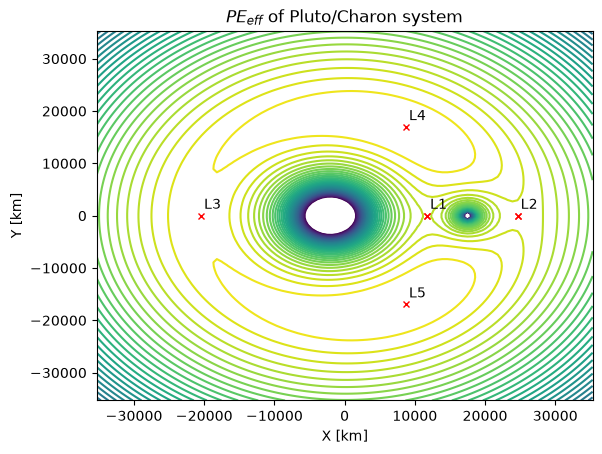

In [221]:
scale = 3
x = np.linspace(-r_L1*scale, r_L1*scale, 100)
y = np.linspace(-r_L1*scale, r_L1*scale, 100)

X, Y = np.meshgrid(x, y)
Z = pe_eff(X, Y)

levels = np.linspace(2*pe_eff(r_bc_charon*0.9,0), np.max(Z), 40)

plt.contour(X, Y, Z, levels)
plt.plot(r_L1, 0, "rx", markersize=5)
plt.plot(r_L2, 0, "rx", markersize=5)


xs = [r_L1, r_L2, r_L3]
labels = ["L1", "L2", "L3"]
for l_point, label in zip(xs, labels):
    plt.plot(l_point, 0, "rx", markersize=5)
    plt.annotate(label, xy=(l_point,0),
                 textcoords="offset points", xytext=(2,5))
    
plt.plot(x_L4_L5, y_L4_L5, "rx", markersize=5)
plt.plot(x_L4_L5, -y_L4_L5, "rx", markersize=5)
plt.annotate("L4", xy=(x_L4_L5, y_L4_L5),
                 textcoords="offset points", xytext=(2,5))
plt.annotate("L5", xy=(x_L4_L5, -y_L4_L5),
                 textcoords="offset points", xytext=(2,5))

plt.title(r"$PE_{eff}$ of Pluto/Charon system")
plt.xlabel("X [km]")
plt.ylabel("Y [km]")
plt.show()

## Problem 2